# 04 · Error analysis

Quantitative and qualitative error analysis of the TF-IDF model (confusion pairs, error rates, top terms per confusion), then example postings for the BERT models: typical samples, errors Section-Aware BERT fixes, cases both models miss (possible label noise), hard Mid-level cases and section extraction examples. Reads prediction files saved by the earlier notebooks.

# **Error Analysis**

TF-IDF:

Quantitative analysis


In [ ]:
errors = test_df.copy()
errors['pred'] = y_pred
errors = errors[errors['experience_level'] != errors['pred']]

print(f"Total misclassified: {len(errors)}")
errors.head()

errors_grouped = errors.groupby(['experience_level', 'pred']).size().sort_values(ascending=False)
print(errors_grouped)



In [ ]:
# Visualize misclassified pairs
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

def generate_error_report(df, true_col="experience_level", pred_col="pred", text_col="text"):

    #Confusion pair counts
    pair_counts = (
        df[df[true_col] != df[pred_col]]
        .groupby([true_col, pred_col])
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

    pair_counts.plot(kind="bar", figsize=(12, 5), color="#E15759")
    plt.title("Top Confusion Pairs")
    plt.ylabel("Count")
    plt.grid(axis="y")
    plt.xticks(rotation=45)
    plt.show()



In [ ]:
test_df["pred"] = y_pred
generate_error_report(test_df,
                      true_col="experience_level",
                      pred_col="pred",
                      text_col="text")

In [ ]:
# error rate
from sklearn.metrics import classification_report
import pandas as pd

test_df["pred"] = y_pred
report = classification_report(
    test_df["experience_level"],
    test_df["pred"],
    output_dict=True
)
df_report = pd.DataFrame(report).T

classes = df_report.loc[df_report.index.isin(['Entry', 'Mid', 'Senior', 'Executive'])].copy()
classes["error_rate"] = 1 - classes["recall"]

result = classes[["precision", "recall", "f1-score", "error_rate", "support"]]

print(result.sort_values(by="error_rate", ascending=False))
result["error_rate"].plot(kind="bar", title="Error Rate by Class", figsize=(8,4))


Qualitative Analysis:



In [ ]:
def sample_confusion(df, actual, pred, n=30):
    subset = df[(df['experience_level']==actual) &
                (df['pred']==pred)]
    return subset.sample(min(n, len(subset)), random_state=42)

entry_senior = sample_confusion(errors, "Entry", "Senior", 50)
senior_entry = sample_confusion(errors, "Senior", "Entry", 50)
mid_senior = sample_confusion(errors, "Mid", "Senior", 30)
mid_entry = sample_confusion(errors, "Mid", "Entry", 50)
exec_senior = sample_confusion(errors, "Executive", "Senior", 50)


In [ ]:
entry_senior.to_csv("entry_to_senior_errors.csv", index=False)
senior_entry.to_csv("senior_to_entry_errors.csv", index=False)
mid_senior.to_csv("mid_to_senior_errors.csv", index=False)
mid_entry.to_csv("mid_to_entry_errors.csv", index=False)
exec_senior.to_csv("exec_to_senior_errors.csv", index=False)

In [ ]:
files = [
    "entry_to_senior_errors.csv",
    "senior_to_entry_errors.csv",
    "mid_to_senior_errors.csv",
    "mid_to_entry_errors.csv",
    "exec_to_senior_errors.csv"
]

dfs = {f: pd.read_csv(f) for f in files}

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

def get_top_tfidf_terms(texts, top_k=20):
    vec = TfidfVectorizer(max_features=5000, stop_words="english")
    X = vec.fit_transform(texts)

    # mean weight per feature
    scores = np.asarray(X.mean(axis=0)).ravel()

    # top indices
    top_idx = scores.argsort()[-top_k:][::-1]
    feature_names = vec.get_feature_names_out()

    return [(feature_names[i], scores[i]) for i in top_idx]


In [ ]:
#Extract top terms for each confusion pair
results = {}

for name, df in dfs.items():
    texts = df["text"].astype(str).tolist()
    top_terms = get_top_tfidf_terms(texts, top_k=20)
    results[name] = top_terms


In [ ]:
#Print results
for name, terms in results.items():
    print("="*80)
    print(f"Top misleading terms for {name.replace('_', ' ')}")
    print("="*80)
    for term, score in terms:
        print(f"{term:<20} {score:.4f}")
    print("\n")


TF-IDF error analysis results

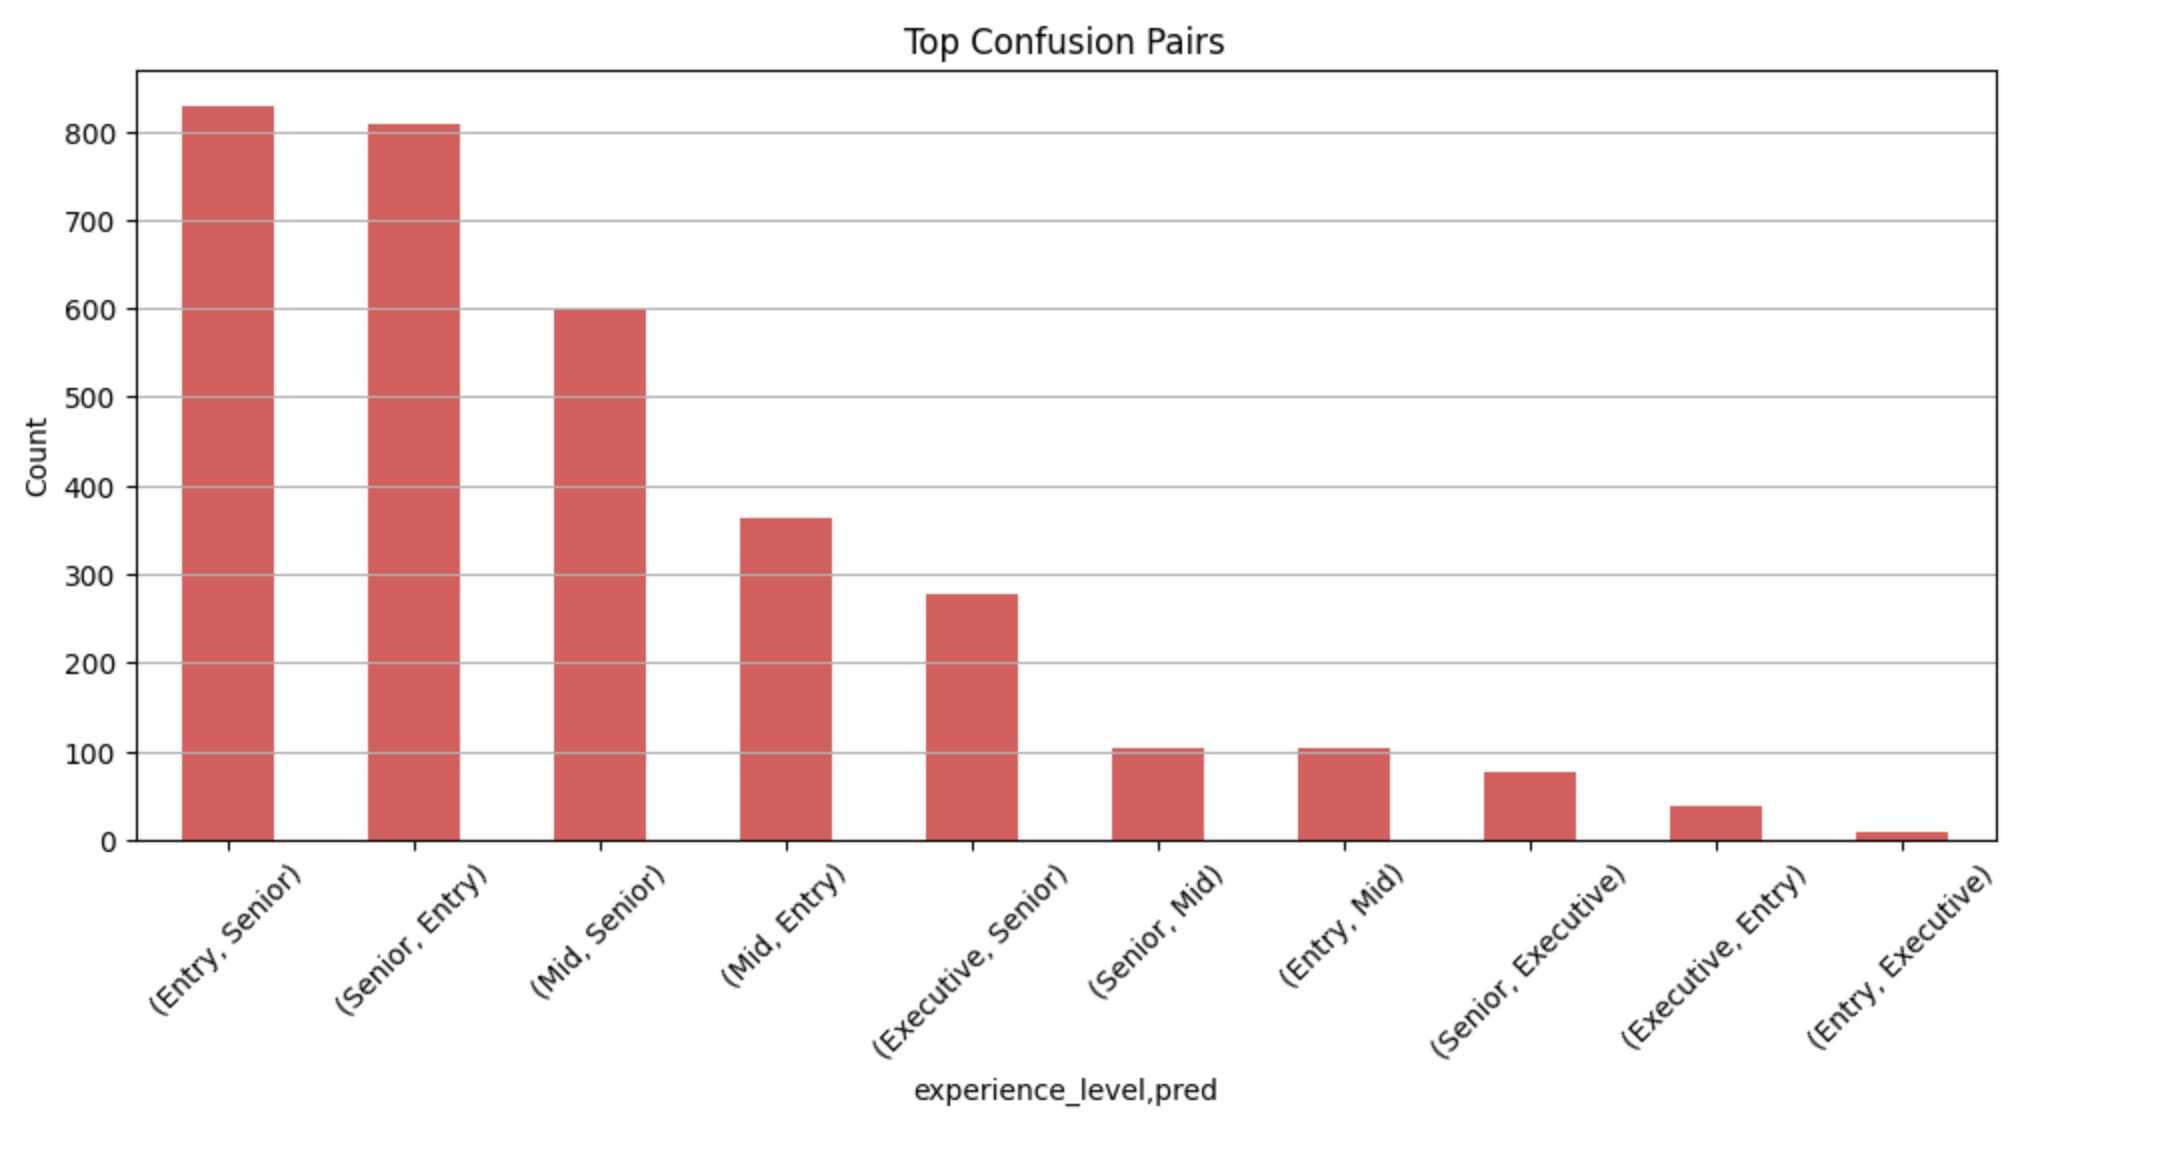

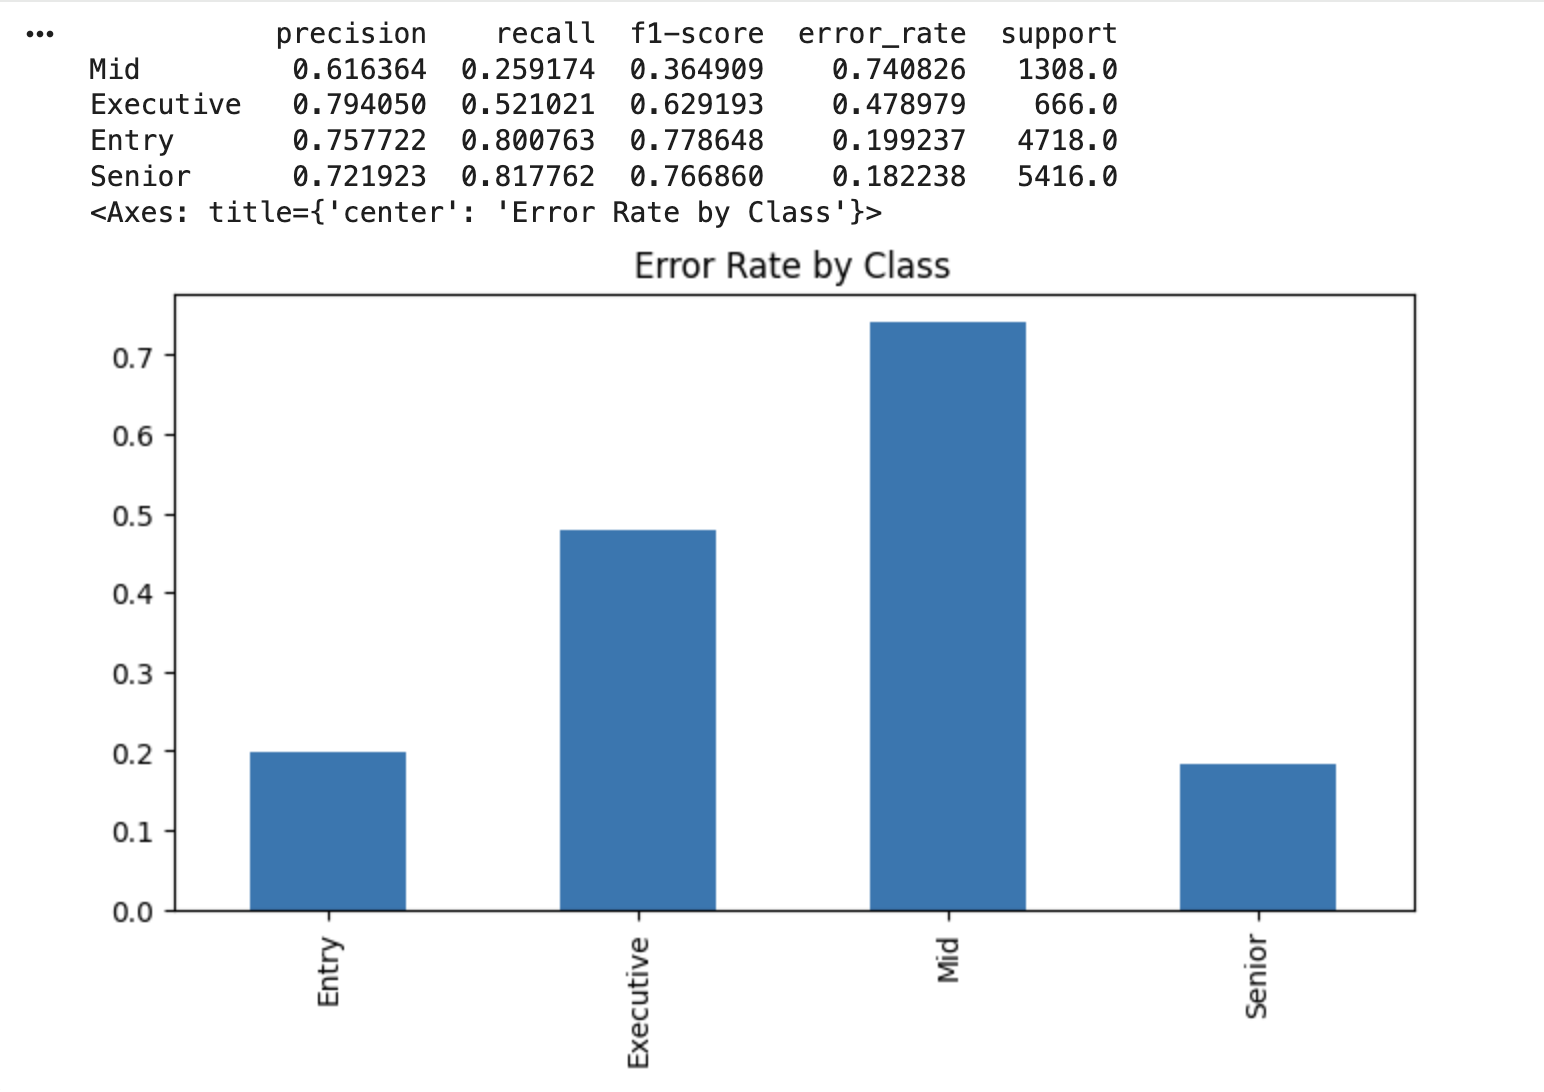

In [ ]:
'''
================================================================================
Top misleading terms for entry to senior errors.csv
================================================================================
project              0.0450
experience           0.0446
data                 0.0426
work                 0.0367
team                 0.0313
skills               0.0307
program              0.0304
financial            0.0304
business             0.0287
required             0.0284
management           0.0267
ability              0.0262
health               0.0261
manager              0.0259
engineering          0.0257
position             0.0245
support              0.0240
knowledge            0.0231
services             0.0228
job                  0.0225


================================================================================
Top misleading terms for senior to entry errors.csv
================================================================================
work                 0.0419
sales                0.0418
customer             0.0373
experience           0.0354
service              0.0350
company              0.0340
team                 0.0326
ability              0.0311
job                  0.0294
including            0.0272
business             0.0269
support              0.0268
patient              0.0251
services             0.0249
required             0.0248
customers            0.0235
care                 0.0233
skills               0.0230
training             0.0230
provide              0.0225


================================================================================
Top misleading terms for mid to senior errors.csv
================================================================================
work                 0.0528
experience           0.0503
business             0.0444
team                 0.0434
support              0.0393
health               0.0345
development          0.0330
skills               0.0321
project              0.0307
management           0.0298
design               0.0297
data                 0.0286
hardware             0.0283
required             0.0283
sales                0.0280
ability              0.0280
job                  0.0277
company              0.0273
position             0.0266
software             0.0265


================================================================================
Top misleading terms for mid to entry errors.csv
================================================================================
experience           0.0433
work                 0.0419
ability              0.0376
customer             0.0330
required             0.0319
sales                0.0317
team                 0.0311
insurance            0.0293
skills               0.0293
equipment            0.0283
electrical           0.0277
client               0.0275
support              0.0274
time                 0.0258
position             0.0252
job                  0.0247
company              0.0246
environment          0.0236
status               0.0235
information          0.0233


================================================================================
Top misleading terms for exec to senior errors.csv
================================================================================
experience           0.0464
business             0.0460
work                 0.0399
management           0.0375
sales                0.0362
company              0.0338
team                 0.0307
services             0.0300
customer             0.0295
ability              0.0293
skills               0.0287
accounting           0.0247
financial            0.0247
planning             0.0242
including            0.0238
tax                  0.0238
product              0.0234
community            0.0233
program              0.0232
support              0.0228




Bert

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch
import torch.nn.functional as F
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

def extract_token_attention(model, input_ids, attention_mask, device='cuda'):
    """Extract token-level attention from BERT"""
    model.eval()
    with torch.no_grad():
        outputs = model.bert(
            input_ids=input_ids.to(device),
            attention_mask=attention_mask.to(device),
            output_attentions=True
        )
        return [attn.cpu().numpy() for attn in outputs.attentions]

def get_cls_attention(attentions, layer=-1):
    """Get [CLS] token attention (last layer, averaged across heads)"""
    layer_attn = attentions[layer]  # [batch, num_heads, seq_len, seq_len]
    layer_attn = layer_attn.mean(axis=1)  # [batch, seq_len, seq_len]
    return layer_attn[:, 0, :]  # [batch, seq_len]

def analyze_keyword_attention(tokens, attention_weights, keywords_dict):
    """Calculate average attention for keyword categories"""
    results = {}

    for category, keywords in keywords_dict.items():
        matched_weights = []

        for token, weight in zip(tokens, attention_weights):
            if token in ['[CLS]', '[SEP]', '[PAD]']:
                continue

            token_clean = token.lower().replace('##', '')
            for keyword in keywords:
                if keyword.lower() in token_clean or token_clean in keyword.lower():
                    matched_weights.append(weight)
                    break

        results[category] = {
            'count': len(matched_weights),
            'avg_attention': np.mean(matched_weights) if matched_weights else 0
        }

    return results

def batch_analyze_attention(model, samples_df, dataset, tokenizer, device='cuda', max_samples=50):
    """Batch analyze attention patterns for multiple samples"""
    all_section_attns = []
    all_keyword_stats = defaultdict(list)

    keywords_dict = {
        'experience_years': ['year', '##s', 'experience', '0', '1', '2', '3', '5', '7', '10', '+'],
        'seniority_level': ['senior', 'junior', 'entry', 'lead', 'principal', 'director', 'executive'],
        'management': ['manage', '##r', '##ment', 'team', 'lead', '##ing', 'supervise', 'oversee'],
        'technical_skills': ['develop', 'design', 'implement', 'code', 'program', 'engineer']
    }

    for idx in samples_df.index[:max_samples]:
        try:
            sample = dataset[idx]

            with torch.no_grad():
                # Section-level attention
                resp_input_ids = sample['resp_input_ids'].unsqueeze(0).to(device)
                resp_attention_mask = sample['resp_attention_mask'].unsqueeze(0).to(device)
                req_input_ids = sample['req_input_ids'].unsqueeze(0).to(device)
                req_attention_mask = sample['req_attention_mask'].unsqueeze(0).to(device)
                other_input_ids = sample['other_input_ids'].unsqueeze(0).to(device)
                other_attention_mask = sample['other_attention_mask'].unsqueeze(0).to(device)

                logits, attn_weights = model(
                    resp_input_ids, resp_attention_mask,
                    req_input_ids, req_attention_mask,
                    other_input_ids, other_attention_mask
                )

                avg_section_attn = attn_weights[0].mean(dim=0).cpu().numpy()
                all_section_attns.append(avg_section_attn)

                # Token-level attention (Requirements section only)
                attentions = extract_token_attention(model, req_input_ids, req_attention_mask, device)
                cls_attn = get_cls_attention(attentions, layer=-1)[0]
                tokens = tokenizer.convert_ids_to_tokens(req_input_ids[0].cpu().numpy())

                keyword_stats = analyze_keyword_attention(tokens, cls_attn, keywords_dict)

                for category, stats in keyword_stats.items():
                    all_keyword_stats[category].append(stats['avg_attention'])

        except Exception as e:
            continue

    avg_section_attn = np.mean(all_section_attns, axis=0)
    avg_keyword_stats = {cat: np.mean(attns) if attns else 0
                         for cat, attns in all_keyword_stats.items()}

    return avg_section_attn, avg_keyword_stats

# Prepare data
test_df_analysis = test_df.copy()
test_df_analysis['pred'] = test_preds_s

errors = test_df_analysis[test_df_analysis['experience_level'] != test_df_analysis['pred']].copy()
correct = test_df_analysis[test_df_analysis['experience_level'] == test_df_analysis['pred']].copy()

print(f"\nTotal: {len(test_df_analysis)} | Correct: {len(correct)} | Errors: {len(errors)}")
print(f"Accuracy: {len(correct)/len(test_df_analysis)*100:.2f}%\n")

# Confusion Matrix
labels = ['Entry', 'Mid', 'Senior', 'Executive']
cm = confusion_matrix(test_df_analysis['experience_level'], test_df_analysis['pred'], labels=labels)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix (Count)')

sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Reds',
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_title('Confusion Matrix (%)')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.close()

# Error Rate by Class
report = classification_report(test_df_analysis['experience_level'],
                               test_df_analysis['pred'],
                               output_dict=True)
df_report = pd.DataFrame(report).T
classes = df_report.loc[df_report.index.isin(labels)].copy()
classes['error_rate'] = 1 - classes['recall']

print("Error Rate by Class:")
print(classes[['precision', 'recall', 'f1-score', 'error_rate', 'support']].sort_values(by='error_rate', ascending=False))
print()

fig, ax = plt.subplots(figsize=(9, 5))
classes_sorted = classes.sort_values(by='error_rate', ascending=False)
bars = ax.bar(classes_sorted.index, classes_sorted['error_rate'] * 100, color='#E15759')
ax.set_ylabel('Error Rate (%)')
ax.set_title('Error Rate by Class')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('error_rate.png', dpi=150, bbox_inches='tight')
plt.close()

# Top Confusion Pairs
confusion_pairs = errors.groupby(['experience_level', 'pred']).size().sort_values(ascending=False).head(10)

print("Top 10 Confusion Pairs:")
print(confusion_pairs)
print()

fig, ax = plt.subplots(figsize=(10, 5))
pair_labels = [f"{true} → {pred}" for true, pred in confusion_pairs.index]
bars = ax.barh(pair_labels, confusion_pairs.values, color='#E15759')
ax.set_xlabel('Count')
ax.set_title('Top 10 Confusion Pairs')
ax.grid(axis='x', alpha=0.3)

for i, bar in enumerate(bars):
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2.,
            f' {int(width)}', ha='left', va='center')

plt.tight_layout()
plt.savefig('confusion_pairs.png', dpi=150, bbox_inches='tight')
plt.close()

# Save error samples
for true_label, pred_label in confusion_pairs.head(5).index:
    samples = errors[(errors['experience_level'] == true_label) & (errors['pred'] == pred_label)]
    samples.to_csv(f"{true_label}_to_{pred_label}_errors.csv", index=False)

print("Saved error samples for top 5 confusion pairs\n")

correct_section_attn, correct_keyword_stats = batch_analyze_attention(
    section_model, correct, test_dataset_sections, tokenizer, device, max_samples=50
)

print("Analyzing error predictions (50 samples)...")
error_section_attn, error_keyword_stats = batch_analyze_attention(
    section_model, errors, test_dataset_sections, tokenizer, device, max_samples=50
)

# Print results
sections = ['Responsibilities', 'Requirements', 'Other']

print("\n" + "-"*80)
print("SECTION ATTENTION COMPARISON")
print("-"*80)

correct_section_importance = correct_section_attn.mean(axis=0)
error_section_importance = error_section_attn.mean(axis=0)

print(f"\n{'Section':<20s} {'Correct':<12s} {'Error':<12s} {'Difference':<12s}")
print("-"*60)
for i, section in enumerate(sections):
    correct_val = correct_section_importance[i]
    error_val = error_section_importance[i]
    diff = error_val - correct_val
    print(f"{section:<20s} {correct_val:<12.3f} {error_val:<12.3f} {diff:+12.3f}")

print("\n" + "-"*80)
print("KEYWORD ATTENTION COMPARISON")
print("-"*80)

categories = list(correct_keyword_stats.keys())
print(f"\n{'Category':<25s} {'Correct':<12s} {'Error':<12s} {'Diff':<12s} {'Change %':<12s}")
print("-"*75)
for category in categories:
    correct_val = correct_keyword_stats[category]
    error_val = error_keyword_stats[category]
    diff = error_val - correct_val
    pct_change = (diff / correct_val * 100) if correct_val > 0 else 0

    print(f"{category:<25s} {correct_val:<12.4f} {error_val:<12.4f} {diff:+12.4f} {pct_change:+11.1f}%")

# Section attention comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
section_labels = ['Resp', 'Req', 'Other']

sns.heatmap(correct_section_attn, annot=True, fmt='.3f', cmap='Greens',
           xticklabels=section_labels, yticklabels=section_labels, ax=axes[0],
           vmin=0, vmax=0.6)
axes[0].set_title('Correct Predictions')

sns.heatmap(error_section_attn, annot=True, fmt='.3f', cmap='Reds',
           xticklabels=section_labels, yticklabels=section_labels, ax=axes[1],
           vmin=0, vmax=0.6)
axes[1].set_title('Error Predictions')

diff = error_section_attn - correct_section_attn
sns.heatmap(diff, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
           xticklabels=section_labels, yticklabels=section_labels, ax=axes[2])
axes[2].set_title('Difference (Error - Correct)')

plt.tight_layout()
plt.savefig('section_attention_comparison.png', dpi=150, bbox_inches='tight')
plt.close()

# Keyword attention comparison
fig, ax = plt.subplots(figsize=(11, 6))

correct_values = [correct_keyword_stats[c] for c in categories]
error_values = [error_keyword_stats[c] for c in categories]

x = np.arange(len(categories))
width = 0.35

bars1 = ax.bar(x - width/2, correct_values, width, label='Correct', color='#70AD47')
bars2 = ax.bar(x + width/2, error_values, width, label='Error', color='#C00000')

ax.set_ylabel('Average Attention Weight')
ax.set_title('Keyword Attention: Correct vs Error')
ax.set_xticks(x)
ax.set_xticklabels(categories, rotation=25, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('keyword_attention_comparison.png', dpi=150, bbox_inches='tight')
plt.close()

keyword_diffs = {cat: error_keyword_stats[cat] - correct_keyword_stats[cat]
                 for cat in categories}
sorted_diffs = sorted(keyword_diffs.items(), key=lambda x: abs(x[1]), reverse=True)

print("\nMost significant attention differences:")
for i, (category, diff) in enumerate(sorted_diffs, 1):
    correct_val = correct_keyword_stats[category]
    error_val = error_keyword_stats[category]
    pct = (diff / correct_val * 100) if correct_val > 0 else 0

    direction = "decreased" if diff < 0 else "increased"
    print(f"{i}. {category}: {direction} by {abs(pct):.1f}% in error predictions")

section_diff_other = error_section_importance[2] - correct_section_importance[2]
section_diff_req = error_section_importance[1] - correct_section_importance[1]

if section_diff_other > 0.05:
    print(f"\n⚠ Other section attention increased significantly in errors (+{section_diff_other:.3f})")
    print("  → Model distracted by irrelevant information")

if section_diff_req < -0.03:
    print(f"\n⚠ Requirements section attention decreased in errors ({section_diff_req:.3f})")
    print("  → Model ignoring key skill/experience requirements")

In [ ]:
import pandas as pd
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

# Load data
df = pd.read_csv(f'{SAVE_DIR}title_aware_bert_predictions.csv')
baseline_df = pd.read_csv(f'{SAVE_DIR}baseline_bert_predictions.csv')
df['pred_baseline'] = baseline_df['pred_baseline_bert']
df['pred_section_aware'] = df['pred_title_aware_bert']

print("=" * 80)
print("SAMPLE INPUT/OUTPUT FOR APPENDIX")
print("=" * 80)

# ============================================================================
# 1. Typical (correctly predicted) samples of each class
# ============================================================================
print("\n" + "=" * 80)
print("1. TYPICAL SAMPLES BY CLASS (Correctly Classified)")
print("=" * 80)

for level in ['Entry', 'Mid', 'Senior', 'Executive']:
    correct = df[(df['experience_level'] == level) &
                 (df['pred_section_aware'] == level)]

    print(f"\n{'='*60}")
    print(f"CLASS: {level.upper()}")
    print(f"{'='*60}")

    # Pick a representative sample
    sample = correct.iloc[0]

    print(f"\nTitle: {sample['title']}")
    print(f"\nResponsibilities (truncated):")
    resp = str(sample.get('section_responsibilities', ''))[:500]
    print(f"  {resp}...")
    print(f"\nRequirements (truncated):")
    req = str(sample.get('section_requirements', ''))[:500]
    print(f"  {req}...")
    print(f"\nTrue Label: {sample['experience_level']}")
    print(f"Predicted: {sample['pred_section_aware']} ✓")

# ============================================================================
# 2. Examples where Section-Aware fixes Baseline errors
# ============================================================================
print("\n" + "=" * 80)
print("2. SECTION-AWARE FIXES BASELINE ERRORS")
print("=" * 80)

section_wins = df[(df['experience_level'] != df['pred_baseline']) &
                  (df['experience_level'] == df['pred_section_aware'])]

for i, (_, sample) in enumerate(section_wins.head(3).iterrows()):
    print(f"\n{'='*60}")
    print(f"EXAMPLE {i+1}")
    print(f"{'='*60}")
    print(f"\nTitle: {sample['title']}")
    print(f"\nResponsibilities (truncated):")
    resp = str(sample.get('section_responsibilities', ''))[:400]
    print(f"  {resp}...")
    print(f"\nRequirements (truncated):")
    req = str(sample.get('section_requirements', ''))[:400]
    print(f"  {req}...")
    print(f"\nTrue Label: {sample['experience_level']}")
    print(f"Baseline Prediction: {sample['pred_baseline']} ✗")
    print(f"Section-Aware Prediction: {sample['pred_section_aware']} ✓")

# ============================================================================
# 3. Examples both models get wrong (possible label noise)
# ============================================================================
print("\n" + "=" * 80)
print("3. BOTH MODELS WRONG (Possible Label Noise)")
print("=" * 80)

both_wrong = df[(df['experience_level'] != df['pred_baseline']) &
                (df['experience_level'] != df['pred_section_aware'])]

for i, (_, sample) in enumerate(both_wrong.head(2).iterrows()):
    print(f"\n{'='*60}")
    print(f"EXAMPLE {i+1}")
    print(f"{'='*60}")
    print(f"\nTitle: {sample['title']}")
    print(f"\nResponsibilities (truncated):")
    resp = str(sample.get('section_responsibilities', ''))[:400]
    print(f"  {resp}...")
    print(f"\nRequirements (truncated):")
    req = str(sample.get('section_requirements', ''))[:400]
    print(f"  {req}...")
    print(f"\nTrue Label: {sample['experience_level']}")
    print(f"Baseline Prediction: {sample['pred_baseline']} ✗")
    print(f"Section-Aware Prediction: {sample['pred_section_aware']} ✗")

# ============================================================================
# 4. Hard Mid-level examples
# ============================================================================
print("\n" + "=" * 80)
print("4. MID-LEVEL DIFFICULTY EXAMPLES")
print("=" * 80)

mid_wrong = df[(df['experience_level'] == 'Mid') &
               (df['pred_section_aware'] != 'Mid')]

for i, (_, sample) in enumerate(mid_wrong.head(2).iterrows()):
    print(f"\n{'='*60}")
    print(f"EXAMPLE {i+1}")
    print(f"{'='*60}")
    print(f"\nTitle: {sample['title']}")
    print(f"\nResponsibilities (truncated):")
    resp = str(sample.get('section_responsibilities', ''))[:400]
    print(f"  {resp}...")
    print(f"\nRequirements (truncated):")
    req = str(sample.get('section_requirements', ''))[:400]
    print(f"  {req}...")
    print(f"\nTrue Label: {sample['experience_level']}")
    print(f"Section-Aware Prediction: {sample['pred_section_aware']} ✗")

print("\n" + "=" * 80)
print("DONE - Use these samples for Appendix")
print("=" * 80)

SAMPLE INPUT/OUTPUT FOR APPENDIX

1. TYPICAL SAMPLES BY CLASS (Correctly Classified)

CLASS: ENTRY

Title: PM Cook - $16 /hr

Responsibilities (truncated):
  High School diploma or equivalent and/or experience in a hotel or a related field preferred.Food Handlers Certification (must comply with State requirements)Must be able to convey information and ideas clearly.Must be able to evaluate and select among alternative courses of action quickly and accurately.Must work well in stressful high pressure situations.Must maintain composure and objectivity under pressure. Responsibilities Approach all encounters with guests and associates in a friendly serv...

Requirements (truncated):
  Responsibilities High School diploma or equivalent and/or experience in a hotel or a related field preferred.Food Handlers Certification (must comply with State requirements)Must be able to convey information and ideas clearly.Must be able to evaluate and select among alternative courses of action quickly an

In [ ]:
import pandas as pd
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

df = pd.read_csv(f'{SAVE_DIR}title_aware_bert_predictions.csv')

print("=" * 80)
print("APPENDIX: DATA FORMAT EXAMPLES")
print("=" * 80)

# ============================================================================
# 1. RAW DATA FORMAT (original fields)
# ============================================================================
print("\n" + "=" * 80)
print("1. DATA FIELDS OVERVIEW")
print("=" * 80)

print(f"\nTotal samples: {len(df)}")
print(f"\nColumns: {list(df.columns)}")

# ============================================================================
# 2. COMPLETE EXAMPLE (one full sample)
# ============================================================================
print("\n" + "=" * 80)
print("2. COMPLETE SAMPLE EXAMPLE")
print("=" * 80)

# Pick a medium-length sample whose sections all have content
for i, row in df.iterrows():
    resp = str(row.get('section_responsibilities', ''))
    req = str(row.get('section_requirements', ''))
    other = str(row.get('section_other', ''))

    # Pick a sample where all four sections have reasonable content
    if len(resp) > 200 and len(req) > 200 and len(other) > 100:
        if row['experience_level'] == 'Senior':  # pick a Senior example
            sample = row
            break

print(f"\n{'='*60}")
print("SAMPLE JOB POSTING (After Preprocessing)")
print(f"{'='*60}")

print(f"\n[TITLE]")
print(f"{sample['title']}")

print(f"\n[DESCRIPTION] (Original, truncated to 800 chars)")
print(f"{str(sample['description'])[:800]}...")

print(f"\n[SECTION: RESPONSIBILITIES] (Extracted)")
print(f"{str(sample['section_responsibilities'])[:600]}...")

print(f"\n[SECTION: REQUIREMENTS] (Extracted)")
print(f"{str(sample['section_requirements'])[:600]}...")

print(f"\n[SECTION: OTHER] (Extracted)")
print(f"{str(sample['section_other'])[:400]}...")

print(f"\n[LABEL]")
print(f"Experience Level: {sample['experience_level']}")

# ============================================================================
# 3. SECTION EXTRACTION EXAMPLES (different cases)
# ============================================================================
print("\n" + "=" * 80)
print("3. SECTION EXTRACTION VARIATIONS")
print("=" * 80)

# 3a. Clear section headers
print("\n--- Case A: Clear Section Headers ---")
for i, row in df.iterrows():
    desc = str(row.get('description', '')).lower()
    if 'responsibilities:' in desc and 'requirements:' in desc:
        print(f"Title: {row['title']}")
        print(f"Description snippet: ...{desc[desc.find('responsibilities'):desc.find('responsibilities')+200]}...")
        print(f"Extracted Responsibilities: {str(row['section_responsibilities'])[:200]}...")
        break

# 3b. Variant headers (e.g., "What you'll do")
print("\n--- Case B: Variant Headers ('What you'll do') ---")
for i, row in df.iterrows():
    desc = str(row.get('description', '')).lower()
    if "what you'll do" in desc or "what you will do" in desc:
        print(f"Title: {row['title']}")
        print(f"Extracted Responsibilities: {str(row['section_responsibilities'])[:200]}...")
        break

# 3c. No explicit headers
print("\n--- Case C: Missing Clear Headers (Fallback) ---")
for i, row in df.iterrows():
    desc = str(row.get('description', '')).lower()
    resp = str(row.get('section_responsibilities', ''))
    if 'responsibilities' not in desc and 'requirements' not in desc and len(resp) > 100:
        print(f"Title: {row['title']}")
        print(f"Description snippet (no headers): {desc[:300]}...")
        print(f"Extracted via fallback: {resp[:200]}...")
        break

# ============================================================================
# 4. CLASS DISTRIBUTION EXAMPLES
# ============================================================================
print("\n" + "=" * 80)
print("4. ONE EXAMPLE PER CLASS")
print("=" * 80)

for level in ['Entry', 'Mid', 'Senior', 'Executive']:
    sample = df[df['experience_level'] == level].iloc[0]
    print(f"\n--- {level.upper()} ---")
    print(f"Title: {sample['title']}")
    print(f"Responsibilities: {str(sample['section_responsibilities'])[:150]}...")
    print(f"Requirements: {str(sample['section_requirements'])[:150]}...")

# ============================================================================
# 5. TOKEN LENGTH STATISTICS
# ============================================================================
print("\n" + "=" * 80)
print("5. SECTION LENGTH STATISTICS")
print("=" * 80)

df['title_len'] = df['title'].fillna('').str.split().str.len()
df['resp_len'] = df['section_responsibilities'].fillna('').str.split().str.len()
df['req_len'] = df['section_requirements'].fillna('').str.split().str.len()
df['other_len'] = df['section_other'].fillna('').str.split().str.len()

print(f"\n{'Section':<20} {'Mean':>10} {'Median':>10} {'Max':>10}")
print("-" * 55)
print(f"{'Title':<20} {df['title_len'].mean():>10.1f} {df['title_len'].median():>10.1f} {df['title_len'].max():>10}")
print(f"{'Responsibilities':<20} {df['resp_len'].mean():>10.1f} {df['resp_len'].median():>10.1f} {df['resp_len'].max():>10}")
print(f"{'Requirements':<20} {df['req_len'].mean():>10.1f} {df['req_len'].median():>10.1f} {df['req_len'].max():>10}")
print(f"{'Other':<20} {df['other_len'].mean():>10.1f} {df['other_len'].median():>10.1f} {df['other_len'].max():>10}")

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

APPENDIX: DATA FORMAT EXAMPLES

1. DATA FIELDS OVERVIEW

Total samples: 12108

Columns: ['title', 'description', 'skills_desc', 'formatted_experience_level', 'experience_level', 'section_responsibilities', 'section_requirements', 'section_other', 'full_text', 'pred_title_aware_bert', 'text']

2. COMPLETE SAMPLE EXAMPLE

SAMPLE JOB POSTING (After Preprocessing)

[TITLE]
Customer Service Representative

[DESCRIPTION] (Original, truncated to 800 chars)
Are you interested in working for the nation’s leading fire protection company and beginning a rewarding and satisfying career that helps save the lives of thousands each year? Do you want to be a part of a growing and expanding team of industry experts? If so, exploring career opportunities with Summit Fire Protection may be right for you!

Summit Fire Protection, a subsidiary of Summit Companies, is a premier firm in the Fire Sprinkler and Fire Life Safety industry with offices throughout the Midwest.

We are seeking a Customer Service Re

In [ ]:
import pandas as pd
import re

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

df = pd.read_csv(f'{SAVE_DIR}title_aware_bert_predictions.csv')

print("=" * 80)
print("SECTION EXTRACTION EXAMPLES (REAL DATA)")
print("=" * 80)

# ============================================================================
# Case A: explicit "Responsibilities" and "Requirements" headers
# ============================================================================
print("\n" + "=" * 70)
print("CASE A: Standard Headers ('Responsibilities', 'Requirements')")
print("=" * 70)

for i, row in df.iterrows():
    desc = str(row['description'])
    desc_lower = desc.lower()

    if 'responsibilities:' in desc_lower and 'requirements:' in desc_lower:
        print(f"\n[TITLE]: {row['title']}")
        print(f"\n[ORIGINAL DESCRIPTION (truncated)]:")
        print(desc[:800])
        print("\n...")
        print(f"\n[EXTRACTED RESPONSIBILITIES]:")
        print(str(row['section_responsibilities'])[:400])
        print(f"\n[EXTRACTED REQUIREMENTS]:")
        print(str(row['section_requirements'])[:400])
        print(f"\n[EXTRACTED OTHER]:")
        print(str(row['section_other'])[:300])
        break

# ============================================================================
# Case B: Variant headers ("What you'll do", "What we're looking for")
# ============================================================================
print("\n" + "=" * 70)
print("CASE B: Variant Headers ('What you'll do')")
print("=" * 70)

for i, row in df.iterrows():
    desc = str(row['description'])
    desc_lower = desc.lower()

    if "what you'll do" in desc_lower or "what you will do" in desc_lower:
        print(f"\n[TITLE]: {row['title']}")
        print(f"\n[ORIGINAL DESCRIPTION (truncated)]:")
        print(desc[:800])
        print("\n...")
        print(f"\n[EXTRACTED RESPONSIBILITIES]:")
        print(str(row['section_responsibilities'])[:400])
        print(f"\n[EXTRACTED REQUIREMENTS]:")
        print(str(row['section_requirements'])[:400])
        print(f"\n[EXTRACTED OTHER]:")
        print(str(row['section_other'])[:300])
        break

# ============================================================================
# Case C: No clear headers (fallback)
# ============================================================================
print("\n" + "=" * 70)
print("CASE C: No Clear Headers (Fallback)")
print("=" * 70)

for i, row in df.iterrows():
    desc = str(row['description'])
    desc_lower = desc.lower()
    resp = str(row['section_responsibilities'])

    # No common header, but sections were extracted
    if ('responsibilities' not in desc_lower and
        'requirements' not in desc_lower and
        'qualifications' not in desc_lower and
        "what you'll" not in desc_lower and
        len(resp) > 100):
        print(f"\n[TITLE]: {row['title']}")
        print(f"\n[ORIGINAL DESCRIPTION (truncated)]:")
        print(desc[:800])
        print("\n...")
        print(f"\n[EXTRACTED RESPONSIBILITIES]:")
        print(str(row['section_responsibilities'])[:400])
        print(f"\n[EXTRACTED REQUIREMENTS]:")
        print(str(row['section_requirements'])[:400])
        print(f"\n[EXTRACTED OTHER]:")
        print(str(row['section_other'])[:300])
        break

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

SECTION EXTRACTION EXAMPLES (REAL DATA)

CASE A: Standard Headers ('Responsibilities', 'Requirements')

[TITLE]: Performance Coach - Maine Celtics

[ORIGINAL DESCRIPTION (truncated)]:
Summary: 
Throughout the Boston Celtics’ storied history, they have long stood for equality and respect, including drafting the first African American player, hiring the first African American coach, and playing the first all-black starting five. The Celtics have won a record 17 NBA Championships spanning five (5) decades, including eight (8) in a row from 1959-1966, and winning their most recent in 2008. In addition, forty-one (41) former Celtics players, management, coaches, or staff have been inducted into the Naismith Memorial Basketball Hall of Fame. In December 2002 the team returned to local ownership for the first time since 1963.
Do you want to be a part of NBA History? Are you passionate about enabling athletes to achieve peak performance? The time to join us is now! We are seeki

...

[EXTRACTE

In [ ]:
import pandas as pd

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

df = pd.read_csv(f'{SAVE_DIR}title_aware_bert_predictions.csv')
baseline_df = pd.read_csv(f'{SAVE_DIR}baseline_bert_predictions.csv')
df['pred_baseline'] = baseline_df['pred_baseline_bert']

print("=" * 80)
print("FINDING BETTER ENTRY→SENIOR FIXED EXAMPLES")
print("=" * 80)

# Entry→Senior Fixed: True=Entry, Baseline=Senior, Section-Aware=Entry
entry_senior_fixed = df[(df['experience_level'] == 'Entry') &
                        (df['pred_baseline'] == 'Senior') &
                        (df['pred_title_aware_bert'] == 'Entry')]

print(f"\nTotal Entry→Senior Fixed samples: {len(entry_senior_fixed)}")

print("\n" + "=" * 80)
print("GOOD EXAMPLES (with valid extraction)")
print("=" * 80)

count = 0
for i, row in entry_senior_fixed.iterrows():
    resp = str(row['section_responsibilities'])
    req = str(row['section_requirements'])
    title = str(row['title'])

    # Skip failed extractions
    if 'click' in resp.lower() or 'apply' in resp.lower():
        continue
    if 'nan' in req.lower() or len(req) < 50:
        continue
    if len(resp) < 100:
        continue
    # Skip career-fair postings
    if 'career fair' in title.lower() or 'job fair' in title.lower():
        continue
    # Skip obvious label noise (3+ years, 5+ years in requirements)
    if '5 years' in req.lower() or '5+ years' in req.lower():
        continue
    if '3 years' in req.lower() or '3+ years' in req.lower():
        continue

    print(f"\n{'='*60}")
    print(f"EXAMPLE {count + 1}")
    print(f"{'='*60}")
    print(f"\nTitle: {title}")
    print(f"\nResponsibilities (truncated):")
    print(f"  {resp[:400]}...")
    print(f"\nRequirements (truncated):")
    print(f"  {req[:400]}...")
    print(f"\nTrue Label: Entry")
    print(f"Baseline: Senior ✗")
    print(f"Section-Aware: Entry ✓")

    count += 1
    if count >= 5:
        break

if count == 0:
    print("\nNo good examples found. Relaxing criteria...")

    # Relax the criteria: only require a basic extraction
    for i, row in entry_senior_fixed.head(20).iterrows():
        resp = str(row['section_responsibilities'])
        req = str(row['section_requirements'])
        title = str(row['title'])

        if 'click' in resp.lower() or 'apply' in resp.lower():
            continue
        if 'career fair' in title.lower():
            continue

        print(f"\n{'='*60}")
        print(f"Title: {title}")
        print(f"Resp: {resp[:300]}...")
        print(f"Req: {req[:300]}...")
        print(f"{'='*60}")

        count += 1
        if count >= 5:
            break

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

FINDING BETTER ENTRY→SENIOR FIXED EXAMPLES

Total Entry→Senior Fixed samples: 296

GOOD EXAMPLES (with valid extraction)

EXAMPLE 1

Title: Process Engineer

Responsibilities (truncated):
  Produce or update competitive intelligence reports following literature reviews to identify the latest technology developments and technology readiness levels of relevant technologiesSupport colleagues with preparing a benchmarking of Levelized Costs of Hydrogen-derived products corresponding to several scales and technologiesPerform technical due diligence on processes for producing and using hyd...

Requirements (truncated):
  Position Qualifications What Is Required Bachelors degree (B.Sc.) in Chemical EngineeringFive (5) years of experience in process engineering with exposure to process modeling with tools such as UniSim or Aspen HYSYS. Demonstrated knowledge level competence with simulation toolsExperience with process/system design, including PFS, PEFS, PFDs, P&IDs, and the ability to design 

In [ ]:
import pandas as pd

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

df = pd.read_csv(f'{SAVE_DIR}title_aware_bert_predictions.csv')
baseline_df = pd.read_csv(f'{SAVE_DIR}baseline_bert_predictions.csv')
df['pred_baseline'] = baseline_df['pred_baseline_bert']

print("=" * 80)
print("FINDING MID→SENIOR FIXED EXAMPLES")
print("=" * 80)

# Mid→Senior Fixed: True=Mid, Baseline=Senior, Section-Aware=Mid
mid_senior_fixed = df[(df['experience_level'] == 'Mid') &
                      (df['pred_baseline'] == 'Senior') &
                      (df['pred_title_aware_bert'] == 'Mid')]

print(f"\nTotal Mid→Senior Fixed samples: {len(mid_senior_fixed)}")

print("\n" + "=" * 80)
print("GOOD EXAMPLES")
print("=" * 80)

count = 0
for i, row in mid_senior_fixed.iterrows():
    resp = str(row['section_responsibilities'])
    req = str(row['section_requirements'])
    title = str(row['title'])

    # Skip failed extractions
    if 'click' in resp.lower() or 'apply' in resp.lower():
        continue
    if 'nan' in req.lower() or len(req) < 50:
        continue
    if len(resp) < 100:
        continue

    print(f"\n{'='*60}")
    print(f"EXAMPLE {count + 1}")
    print(f"{'='*60}")
    print(f"\nTitle: {title}")
    print(f"\nResponsibilities (truncated):")
    print(f"  {resp[:400]}...")
    print(f"\nRequirements (truncated):")
    print(f"  {req[:400]}...")
    print(f"\nTrue Label: Mid")
    print(f"Baseline: Senior ✗")
    print(f"Section-Aware: Mid ✓")

    count += 1
    if count >= 5:
        break

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

FINDING MID→SENIOR FIXED EXAMPLES

Total Mid→Senior Fixed samples: 80

GOOD EXAMPLES

EXAMPLE 1

Title: Orthopedics Distributor

Responsibilities (truncated):
  CONMED has been leading the development of cutting-edge surgical and patient care products since the early 1970s. We believe it is our capacity to innovate that sets us apart. We iterate on our products to ensure clinical excellence and embrace a mindset of constant improvement. As a result, we have come to own numerous areas of innovation including our Orthopedics division. CONMED’s Orthopedics P...

Requirements (truncated):
  fluid management, resection, ablation, surgical imaging, powered instruments, biologics as well as our newly acquired BioBrace Implant. At CONMED Orthopedics, innovation is priority - the team is constantly designing and developing new products such as the world’s first autoclavable HD camera head and the world's first self-punching all-suture anchor with tape. As CONMED Orthopedics continues to g...

T

In [ ]:
import pandas as pd

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

df = pd.read_csv(f'{SAVE_DIR}title_aware_bert_predictions.csv')
baseline_df = pd.read_csv(f'{SAVE_DIR}baseline_bert_predictions.csv')
df['pred_baseline'] = baseline_df['pred_baseline_bert']

print("=" * 80)
print("MID-LEVEL: BOTH MODELS WRONG")
print("=" * 80)

# True=Mid, but neither model predicted Mid
mid_both_wrong = df[(df['experience_level'] == 'Mid') &
                    (df['pred_baseline'] != 'Mid') &
                    (df['pred_title_aware_bert'] != 'Mid')]

print(f"\nTotal Mid both wrong: {len(mid_both_wrong)}")

# Group by prediction
print("\nPrediction patterns:")
print(mid_both_wrong.groupby(['pred_baseline', 'pred_title_aware_bert']).size())

print("\n" + "=" * 80)
print("GOOD EXAMPLES")
print("=" * 80)

count = 0
for i, row in mid_both_wrong.iterrows():
    resp = str(row['section_responsibilities'])
    req = str(row['section_requirements'])
    title = str(row['title'])

    # Skip failed extractions
    if 'click' in resp.lower() or 'apply' in resp.lower():
        continue
    if 'nan' in req.lower() or len(req) < 50:
        continue
    if len(resp) < 100:
        continue
    # Skip ones already used
    if 'Performance Coach' in title:
        continue

    print(f"\n{'='*60}")
    print(f"EXAMPLE {count + 1}")
    print(f"{'='*60}")
    print(f"\nTitle: {title}")
    print(f"\nResponsibilities (truncated):")
    print(f"  {resp[:400]}...")
    print(f"\nRequirements (truncated):")
    print(f"  {req[:400]}...")
    print(f"\nTrue Label: Mid")
    print(f"Baseline: {row['pred_baseline']} ✗")
    print(f"Section-Aware: {row['pred_title_aware_bert']} ✗")

    count += 1
    if count >= 5:
        break

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

MID-LEVEL: BOTH MODELS WRONG

Total Mid both wrong: 534

Prediction patterns:
pred_baseline  pred_title_aware_bert
Entry          Entry                    130
               Senior                    27
Executive      Executive                  5
               Senior                     3
Senior         Entry                     19
               Executive                  2
               Senior                   348
dtype: int64

GOOD EXAMPLES

EXAMPLE 1

Title: Financial Advisor - Greenwood, IN

Responsibilities (truncated):
  Meaningful work. Rewarding career. Make an impact providing holistic purpose-based financial advice to clients, helping them achieve their goals. You’ll enjoy the satisfaction of making a difference in the lives of the people you serve while also having control over the income you earn, as you’ll be paid through commissions and incentives based on your success. At Thrivent, you’ll receive the supp...

Requirements (truncated):
  Bachelor’s degree or equivalen